# GRPO: Mengajari Model "Berpikir" sebelum Menjawab (Kriteria 1 — Advanced)

**Proyek Akhir — Pengembangan Generative AI berbasis LLM (Dicoding)** · Romi Fadli

Model instruct buatan kita sendiri (`tnromy/Qwen2.5-1.5B-Legal-ID-SFT`, hasil notebook Fine-tuning)
dilatih lanjut dengan **Group Relative Policy Optimization** (TRL `GRPOTrainer` + Unsloth) agar
selalu menuliskan proses penalaran di dalam `<think> ... </think>` sebelum memberikan jawaban akhir
berbahasa Indonesia. Dataset tetap `Ichsan2895/alpaca-gpt4-indonesian`.

Empat reward function:

| Reward | Aturan |
|---|---|
| `format_reward_func` | `<think>` +0.2, `</think>` +0.3, format sempurna = +1.0; tag ganda −0.5 |
| `reasoning_length_reward` | isi `<think>`: kosong 0.0, <50 karakter 0.2, 50–199 0.5, ≥200 1.0 (toleran bila terpotong) |
| `correctness_reward` | +1.0 bila jawaban akhir memuat ground truth atau ROUGE-L ≥ 0.3 terhadap kolom `output` |
| `language_reward_func` | −0.5 bila jawaban berbahasa Inggris, +1.0 bila murni bahasa Indonesia |

## 1. Instalasi & konfigurasi

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "unsloth"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'unsloth'], returncode=0)

In [2]:
import os, re, random
import torch
from kaggle_secrets import UserSecretsClient

os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
SFT_MODEL = "tnromy/Qwen2.5-1.5B-Legal-ID-SFT"
HF_REPO = "tnromy/Qwen2.5-1.5B-Legal-ID-GRPO"
MAX_SEQ_LEN = 1024
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 2. Memuat kembali model instruct buatan sendiri (QLoRA 4-bit + double quantization)

In [3]:
from unsloth import FastLanguageModel
from transformers import BitsAndBytesConfig

bnb_config = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=SFT_MODEL, max_seq_length=MAX_SEQ_LEN, dtype=None, load_in_4bit=True,
    quantization_config=bnb_config, token=os.environ["HF_TOKEN"])
model = FastLanguageModel.get_peft_model(
    model, r=16, lora_alpha=32, lora_dropout=0, bias="none",
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    use_gradient_checkpointing="unsloth", random_state=SEED)
model.print_trainable_parameters()

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.1: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth 2026.11.1 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


## 3. Dataset prompt untuk GRPO
Dipilih contoh dengan jawaban yang tidak terlalu panjang agar `correctness_reward` dapat dinilai dalam
batas `max_completion_length`. Prompt yang terlalu panjang dibuang (pengganti `max_prompt_length`).

In [4]:
from datasets import load_dataset

SYSTEM_PROMPT = (
    "Anda adalah asisten AI berbahasa Indonesia. Sebelum menjawab, tuliskan proses berpikir Anda "
    "di antara tag <think> dan </think>, kemudian tuliskan jawaban akhir dalam bahasa Indonesia.\n"
    "Format:\n<think>\n...penalaran langkah demi langkah...\n</think>\n...jawaban akhir..."
)

raw = load_dataset("Ichsan2895/alpaca-gpt4-indonesian", split="train").shuffle(seed=SEED)
raw = raw.filter(lambda r: r["input"] and r["output"] and len(r["input"]) < 400 and 30 < len(r["output"]) < 400)
raw = raw.select(range(800))

def to_prompt(r):
    return {"prompt": [{"role": "system", "content": SYSTEM_PROMPT},
                       {"role": "user", "content": r["input"].strip()}],
            "answer": r["output"].strip()}

grpo_ds = raw.map(to_prompt, remove_columns=raw.column_names)
lengths = [len(tokenizer.apply_chat_template(p, add_generation_prompt=True)) for p in grpo_ds["prompt"]]
grpo_ds = grpo_ds.select([i for i, n in enumerate(lengths) if n <= 256])
print(grpo_ds)
print(grpo_ds[0])

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

alpaca-gpt4-indonesia.csv: reconstructing file:   0%|          |  0.00B / 41.4MB            

alpaca-gpt4-indonesia.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/49969 [00:00<?, ? examples/s]

Filter:   0%|          | 0/49969 [00:00<?, ? examples/s]

Map:   0%|          | 0/800 [00:00<?, ? examples/s]

Dataset({
    features: ['prompt', 'answer'],
    num_rows: 800
})
{'prompt': [{'content': 'Anda adalah asisten AI berbahasa Indonesia. Sebelum menjawab, tuliskan proses berpikir Anda di antara tag <think> dan </think>, kemudian tuliskan jawaban akhir dalam bahasa Indonesia.\nFormat:\n<think>\n...penalaran langkah demi langkah...\n</think>\n...jawaban akhir...', 'role': 'system'}, {'content': 'Ubahlah kalimat tersebut agar menggunakan kata ganti objek.\nDia sedang mengemudi terlalu cepat.', 'role': 'user'}], 'answer': 'Mengemudikannya terlalu cepat tidak aman.'}


## 4. Reward functions

In [5]:
THINK_OPEN, THINK_CLOSE = "<think>", "</think>"

def _text(completion):
    return completion[0]["content"] if isinstance(completion, list) else completion

def split_think(text):
    """Kembalikan (isi_think, jawaban_akhir). Toleran bila </think> terpotong batas token."""
    if THINK_OPEN not in text:
        return None, text.strip()
    after = text.split(THINK_OPEN, 1)[1]
    if THINK_CLOSE in after:
        thought, final = after.split(THINK_CLOSE, 1)
        return thought.strip(), final.strip()
    return after.strip(), ""

def format_reward_func(completions, **kwargs):
    rewards = []
    for c in completions:
        t = _text(c)
        score = 0.0
        if THINK_OPEN in t:
            score += 0.2
        if THINK_CLOSE in t:
            score += 0.3
        perfect = re.match(r"^\s*<think>.+?</think>\s*\S", t, flags=re.S)
        if perfect and t.count(THINK_OPEN) == 1 and t.count(THINK_CLOSE) == 1:
            score = 1.0
        if t.count(THINK_OPEN) > 1 or t.count(THINK_CLOSE) > 1:
            score -= 0.5
        rewards.append(score)
    return rewards

def reasoning_length_reward(completions, **kwargs):
    rewards = []
    for c in completions:
        thought, _ = split_think(_text(c))
        if not thought:
            rewards.append(0.0)
        elif len(thought) < 50:
            rewards.append(0.2)
        elif len(thought) < 200:
            rewards.append(0.5)
        else:
            rewards.append(1.0)
    return rewards

def _tokens(s):
    return re.findall(r"\w+", s.lower())

def rouge_l_f(candidate, reference):
    a, b = _tokens(candidate), _tokens(reference)
    if not a or not b:
        return 0.0
    dp = [0] * (len(b) + 1)
    for x in a:
        prev = 0
        for j, y in enumerate(b, 1):
            cur = dp[j]
            dp[j] = prev + 1 if x == y else max(dp[j], dp[j - 1])
            prev = cur
    lcs = dp[-1]
    if lcs == 0:
        return 0.0
    p, r = lcs / len(a), lcs / len(b)
    return 2 * p * r / (p + r)

def correctness_reward(completions, answer, **kwargs):
    rewards = []
    for c, gt in zip(completions, answer):
        _, final = split_think(_text(c))
        final = final or _text(c)
        exact = " ".join(_tokens(gt)) in " ".join(_tokens(final))
        rewards.append(1.0 if exact or rouge_l_f(final, gt) >= 0.3 else 0.0)
    return rewards

EN_WORDS = set("the and is are of to in that it for with as was this be on not by or from at which you your".split())
ID_WORDS = set("yang dan di ke dari ini itu dengan untuk adalah pada dalam tidak akan atau juga karena".split())

def language_reward_func(completions, **kwargs):
    rewards = []
    for c in completions:
        _, final = split_think(_text(c))
        words = _tokens(final or _text(c))
        en = sum(w in EN_WORDS for w in words)
        idn = sum(w in ID_WORDS for w in words)
        if en > idn or en >= 3:
            rewards.append(-0.5)
        elif idn > 0 and en == 0:
            rewards.append(1.0)
        else:
            rewards.append(0.0)
    return rewards

REWARDS = [format_reward_func, reasoning_length_reward, correctness_reward, language_reward_func]

Uji cepat reward function pada beberapa contoh buatan.

In [6]:
samples = [
    "<think>Pengguna bertanya tentang ibu kota. Ibu kota Indonesia adalah Jakarta, sesuai fakta umum yang "
    "diketahui banyak orang dan tercatat dalam berbagai sumber resmi pemerintahan maupun buku pelajaran.</think>"
    " Ibu kota Indonesia adalah Jakarta.",
    "<think>singkat</think> The capital is Jakarta.",
    "Ibu kota Indonesia adalah Jakarta.",
    "<think>a</think><think>b</think> Jakarta",
    "<think>Penalaran ini terpotong karena batas token sehingga tag penutup tidak sempat",
]
comps = [[{"role": "assistant", "content": s}] for s in samples]
gts = ["Ibu kota Indonesia adalah Jakarta."] * len(samples)
import pandas as pd
pd.DataFrame({f.__name__: f(comps, answer=gts) for f in REWARDS}, index=[s[:45] for s in samples])

,format_reward_func,reasoning_length_reward,correctness_reward,language_reward_func
<think>Pengguna bertanya tentang ibu kota. Ib,1.0,0.5,1.0,1.0
<think>singkat</think> The capital is Jakarta,1.0,0.2,0.0,-0.5
Ibu kota Indonesia adalah Jakarta.,0.0,0.0,1.0,1.0
<think>a</think><think>b</think> Jakarta,0.0,0.2,0.0,0.0
<think>Penalaran ini terpotong karena batas t,0.2,0.5,0.0,1.0


## 5. Training GRPO
`num_generations=6` dan `max_completion_length=320` dipilih agar muat di VRAM T4 (16 GB) tanpa OOM.
Model SFT hampir tidak pernah menulis `<think>` sendiri, sehingga sinyal reward awal sangat jarang.
Karena itu learning rate dibuat cukup besar untuk LoRA (3e-5), temperature 1.0 untuk eksplorasi,
dan 6 generasi per prompt agar setiap grup lebih mungkin berisi minimal satu jawaban berformat benar.

In [7]:
from trl import GRPOConfig, GRPOTrainer

args = GRPOConfig(
    output_dir="outputs/grpo",
    per_device_train_batch_size=6,
    gradient_accumulation_steps=1,
    num_generations=6,
    max_completion_length=320,
    max_steps=200,
    learning_rate=3e-5,
    lr_scheduler_type="cosine",
    warmup_steps=6,
    temperature=1.0,
    optim="adamw_8bit",
    fp16=True,
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    seed=SEED,
)
trainer = GRPOTrainer(model=model, processing_class=tokenizer, reward_funcs=REWARDS,
                      train_dataset=grpo_ds, args=args)
train_result = trainer.train()
print(train_result)

Unsloth: GRPO now defaults to TRL's loss_type = 'dapo' with beta = 0.0. Set loss_type = 'bnpo', beta = 0.001 for Unsloth's previous default.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 800 | Num Epochs = 1 | Total steps = 200
O^O/ \_/ \    Batch size per device = 6 | Gradient accumulation steps = 1
\        /    Data Parallel GPUs = 1 | Total batch size (6 x 1 x 1) = 6
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)
Passing `generation_config` together with generation-related arguments=({'pad_token_id', 'cache_implementation'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=320) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. 

Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: GRPO PrefixGrouper is off: its flex attention kernel does not compile with torch 2.11.0+cu130 on this GPU (RuntimeError: No valid triton configs. OutOfMemoryError: out of resource: triton_tem_fused_flex_attention_0 Required: 98304 Hardware limit:65536 Reducing block sizes or `num_stages` may help.); using the packed path.


Step,Training Loss,reward,reward_std,completions / mean_length,completions / min_length,completions / max_length,completions / clipped_ratio,completions / mean_terminated_length,completions / min_terminated_length,completions / max_terminated_length,kl,rewards / format_reward_func / mean,rewards / format_reward_func / std,rewards / reasoning_length_reward / mean,rewards / reasoning_length_reward / std,rewards / correctness_reward / mean,rewards / correctness_reward / std,rewards / language_reward_func / mean,rewards / language_reward_func / std
10,-0.157209,1.120000,0.795184,101.133338,26.800000,208.100000,0.066667,86.860002,26.800000,177.200000,0.000000,0.070000,0.133280,0.133333,0.201389,0.183333,0.283659,0.733333,0.458133
20,0.025168,1.048333,0.651857,134.266669,28.800000,247.600000,0.183333,97.028336,28.800000,205.800000,0.000000,0.075000,0.100244,0.165000,0.238180,0.133333,0.258896,0.675000,0.438671
30,-0.104025,1.221667,0.583119,109.150005,43.900000,212.300000,0.083333,92.741670,43.900000,167.400000,0.000000,0.130000,0.249615,0.208333,0.271484,0.083333,0.106412,0.800000,0.301810
40,-0.132671,1.281667,0.788873,121.066672,37.600000,235.300000,0.133333,97.056670,37.600000,187.400000,0.000000,0.190000,0.273005,0.275000,0.275206,0.150000,0.122474,0.666667,0.500686
50,0.032335,1.855000,0.647136,210.483340,78.700000,299.700000,0.350000,158.980001,78.700000,248.300000,0.000000,0.266667,0.382096,0.605000,0.302243,0.100000,0.184929,0.883333,0.218072
60,-0.008939,2.066667,0.748453,165.200005,67.000000,293.000000,0.216667,130.656670,67.000000,239.600000,0.000000,0.625000,0.436187,0.600000,0.285019,0.133333,0.198877,0.708333,0.483686
70,0.077918,2.038333,0.878910,197.983341,84.700000,305.100000,0.233333,162.235002,84.700000,240.200000,0.000000,0.478333,0.509530,0.701667,0.306597,0.100000,0.184929,0.758333,0.385347
80,0.010468,2.256667,0.705119,163.383338,58.100000,291.900000,0.183333,130.500002,58.100000,222.000000,0.000000,0.691667,0.451636,0.681667,0.325647,0.133333,0.228887,0.750000,0.366619
90,0.023679,2.165000,0.637628,220.033337,107.400000,313.700000,0.250000,192.300002,107.400000,277.700000,0.000000,0.648333,0.370403,0.858333,0.197310,0.016667,0.040825,0.641667,0.473093
100,-0.044181,2.271667,0.668038,166.716669,78.400000,286.900000,0.066667,155.898335,78.400000,253.600000,0.000000,0.753333,0.373404,0.701667,0.248884,0.083333,0.144104,0.733333,0.445914


Both `max_new_tokens` (=320) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Both `max_new_tokens` (=320) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=320) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

TrainOutput(global_step=200, training_loss=-0.022916378192603587, metrics={'train_runtime': 6078.647, 'train_samples_per_second': 0.197, 'train_steps_per_second': 0.033, 'total_flos': 0.0, 'train_loss': -0.022916378192603587, 'epoch': 0.25})


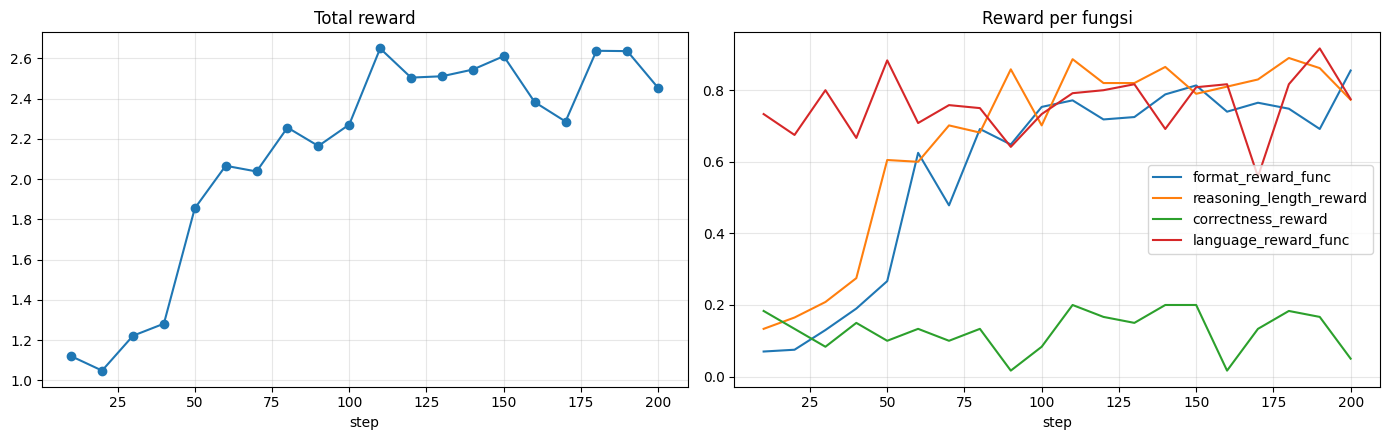

,step,reward,rewards/format_reward_func/mean,rewards/reasoning_length_reward/mean,rewards/correctness_reward/mean,rewards/language_reward_func/mean
10,110,2.650000,0.771667,0.886667,0.200000,0.791667
11,120,2.505000,0.718333,0.820000,0.166667,0.800000
12,130,2.511667,0.725000,0.820000,0.150000,0.816667
13,140,2.545000,0.788333,0.865000,0.200000,0.691667
14,150,2.611667,0.813333,0.790000,0.200000,0.808333
15,160,2.383333,0.740000,0.810000,0.016667,0.816667
16,170,2.286667,0.765000,0.830000,0.133333,0.558333
17,180,2.638333,0.748333,0.890000,0.183333,0.816667
18,190,2.636667,0.691667,0.861667,0.166667,0.916667
19,200,2.453333,0.855000,0.773333,0.050000,0.775000


In [8]:
import matplotlib.pyplot as plt

hist = pd.DataFrame(trainer.state.log_history).dropna(subset=["reward"])
cols = [c for c in hist.columns if c.startswith("rewards/") and c.endswith("/mean")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(hist["step"], hist["reward"], marker="o"); axes[0].set_title("Total reward")
for c in cols:
    axes[1].plot(hist["step"], hist[c], label=c.split("/")[1])
axes[1].set_title("Reward per fungsi"); axes[1].legend()
for ax in axes:
    ax.set_xlabel("step"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
hist[["step", "reward"] + cols].tail(10)

## 6. Uji model hasil GRPO
Dua mode diuji:
1. **Bebas** — model menulis responsnya sendiri dari awal.
2. **Reasoning trigger** — giliran asisten diawali `<think>\n` (praktik yang direkomendasikan untuk
   model reasoning seperti DeepSeek-R1). Generasi dihentikan bila model mulai membuka `<think>` kedua.
   Mode ini yang dipakai di pipeline RAG.

In [9]:
from transformers import StoppingCriteria, StoppingCriteriaList

FastLanguageModel.for_inference(model)

class StopOnSecondThink(StoppingCriteria):
    def __init__(self, start): self.start = start
    def __call__(self, input_ids, scores, **kw):
        t = tokenizer.decode(input_ids[0][self.start:], skip_special_tokens=True)
        return THINK_CLOSE in t and THINK_OPEN in t.split(THINK_CLOSE, 1)[1]

def ask(question, trigger=False, max_new_tokens=400):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    text = tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)
    prefix = THINK_OPEN + "\n" if trigger else ""
    ids = tokenizer(text + prefix, return_tensors="pt").input_ids.to("cuda")
    out = model.generate(input_ids=ids, max_new_tokens=max_new_tokens, temperature=0.3, do_sample=True,
                         repetition_penalty=1.1,
                         stopping_criteria=StoppingCriteriaList([StopOnSecondThink(ids.shape[1])]))
    resp = prefix + tokenizer.decode(out[0][ids.shape[1]:], skip_special_tokens=True)
    if THINK_CLOSE in resp:  # buang blok <think> tambahan yang terlanjur dimulai
        head, tail = resp.split(THINK_CLOSE, 1)
        resp = head + THINK_CLOSE + tail.split(THINK_OPEN, 1)[0]
    return resp.strip()

for q in ["Jelaskan perbedaan antara pekerja tetap dan pekerja kontrak.",
          "Saya staf admin, kemarin lembur 3 jam untuk beresin laporan. Apakah saya berhak dapat uang lembur?"]:
    for trigger in (False, True):
        resp = ask(q, trigger)
        comp = [[{"content": resp}]]
        scores = {f.__name__: f(comp)[0] for f in (format_reward_func, reasoning_length_reward, language_reward_func)}
        print(f"### {q}  [{'reasoning trigger' if trigger else 'bebas'}]\n{resp}\n{scores}\n")

Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


### Jelaskan perbedaan antara pekerja tetap dan pekerja kontrak.  [bebas]
<think>
Pekerja tetap dan pekerja kontrak adalah dua jenis kerja yang sering digunakan oleh organisasi untuk menghasilkan produk atau layanan. Namun, ada beberapa perbedaan kunci antara kedua jenis pekerja ini.

1. Perjanjian Kerja: Pekerja tetap memiliki kontrak legal yang ditandatangani dengan perusahaan, sementara pekerja kontrak bekerja pada waktu singkat dan biasanya tidak memiliki kontrak permanen. Kontrak kontrak dapat bervariasi dari satu bulan hingga satu tahun, tergantung pada kebutuhan perusahaan.

2. Gaji: Pekerja tetap menerima gaji yang lebih stabil dibandingkan dengan pekerja kontrak. Ini karena mereka bekerja pada waktu yang lebih lama dan memiliki penilaian masa jabatan yang lebih baik. Selain itu, pekerja tetap juga mendapatkan insentif seperti bonus dan tunjangan lainnya.

3. Kepemilikan Modal: Pekerja tetap memiliki hak atas modal perusahaan dan mempunyai tanggung jawab resmi atas bisnis terse

Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


### Jelaskan perbedaan antara pekerja tetap dan pekerja kontrak.  [reasoning trigger]
<think>
Pekerja tetap adalah karyawan yang memiliki kontrak yang jelas dengan perusahaan atau organisasi, dimana mereka diberikan gaji tetap, sumber daya kerja, dan keamanan kerja untuk bekerja secara aktif selama masa kerja. Pekerja tetap biasanya memiliki opsi untuk meningkatkan pangkat atau jabatan melalui upah tambahan.

Sementara itu, pekerja kontrak adalah karyawan yang bekerja untuk perusahaan atau organisasi sebagai tugas-tugas sementara, seringkali dalam bentuk proyek atau projek. Karyawan ini tidak memiliki kontrak formal, dan dapat mengambil pekerjaannya pada waktu lain, dan biasanya mendapatkan gaji sesuai dengan upahnya. Pekerja kontrak juga mungkin memiliki opsi untuk meningkatkan pangkat atau jabatan melalui upah tambahan.
</think>

Jawaban Akhir:
Perbedaan utama antara pekerja tetap dan pekerja kontrak adalah bahwa pekerja tetap memiliki kontrak formal, sedangkan pekerja kontrak bekerj

Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


### Saya staf admin, kemarin lembur 3 jam untuk beresin laporan. Apakah saya berhak dapat uang lembur?  [bebas]
<think>
1. Memeriksa kebijakan perusahaan tentang lemburan: Saya harus memeriksa persyaratan perusahaan terkait lemburan dan apakah ada batasan waktu atau jumlah yang diperbolehkan.
2. Mengecek status pekerjaan: Saya harus melihat apakah ada laporan yang telah dibuat dengan benar dan sudah diproses oleh tim penyusun laporan.
3. Menghitung biaya lemburan: Saya harus menghitung biaya lemburan, termasuk gaji tambahan, insentif, dan potongan pajak.
4. Membandingkan biaya lemburan dengan penghasilan total: Saya harus mengevaluasi apakah penghasilan setelah lemburan lebih besar daripada sebelumnya, dan apakah itu wajar atau tidak.
5. Membahas dengan manajer: Saya akan membahas masalah ini dengan manajer saya dan mencoba mendapatkan bantuan jika diperlukan.
6. Menyimpan hasil: Setelah menyelesaikan semua langkah-langkah ini, saya akan menyimpan hasil dan memberitahu karyawan saya te

## 7. Push model GRPO ke Hugging Face Hub (`merged_16bit`)

In [10]:
model.push_to_hub_merged(HF_REPO, tokenizer, save_method="merged_16bit", token=os.environ["HF_TOKEN"])
from huggingface_hub import HfApi
info = HfApi(token=os.environ["HF_TOKEN"]).model_info(HF_REPO)
print(f"https://huggingface.co/{HF_REPO} | private: {info.private}")

No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub.hf_api|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.
Unsloth: Restored added_tokens_decoder metadata in tnromy/Qwen2.5-1.5B-Legal-ID-GRPO/tokenizer_config.json.
No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub._upload_pipeline|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...


Unsloth: Copying 1 files from cache to `tnromy/Qwen2.5-1.5B-Legal-ID-GRPO`: 100%|██████████| 1/1 [00:01<00:00,  1.98s/it]


Successfully copied all 1 files from cache to `tnromy/Qwen2.5-1.5B-Legal-ID-GRPO`
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Merging weights into 16bit:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:45<00:00, 45.85s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/tnromy/Qwen2.5-1.5B-Legal-ID-GRPO`
https://huggingface.co/tnromy/Qwen2.5-1.5B-Legal-ID-GRPO | private: False
